In [1]:
import pandas as pd
df=pd.read_csv(r"C:\Users\lenovo\Desktop\PROJECTS REFER\Weather Data Analysis\Data.csv")
print(df)

          Date  Temperature  Humidity  WindSpeed  Rainfall
0   01-01-2024         29.5        74       17.3       5.0
1   02-01-2024         27.6        55       13.3       3.5
2   03-01-2024         29.9        72       12.9       0.0
3   04-01-2024         32.6        69        8.6       0.0
4   05-01-2024         27.3        83        6.4       0.0
..         ...          ...       ...        ...       ...
85  26-03-2024         26.5        74       17.2       0.0
86  27-03-2024         30.7        86       18.0       0.5
87  28-03-2024         29.0        79       18.7       0.0
88  29-03-2024         26.4        51       12.7       7.2
89  30-03-2024         29.5        60       12.5       7.2

[90 rows x 5 columns]


In [2]:
df.head(5)

,Date,Temperature,Humidity,WindSpeed,Rainfall
0,01-01-2024,29.5,74,17.3,5.0
1,02-01-2024,27.6,55,13.3,3.5
2,03-01-2024,29.9,72,12.9,0.0
3,04-01-2024,32.6,69,8.6,0.0
4,05-01-2024,27.3,83,6.4,0.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         90 non-null     object 
 1   Temperature  90 non-null     float64
 2   Humidity     90 non-null     int64  
 3   WindSpeed    90 non-null     float64
 4   Rainfall     90 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 3.6+ KB


In [4]:
df.describe() #Descriptive statistics

,Temperature,Humidity,WindSpeed,Rainfall
count,90.000000,90.000000,90.000000,90.000000
mean,27.701111,66.433333,13.282222,2.377778
std,2.806433,13.270776,4.371578,2.703630
min,20.100000,45.000000,5.100000,0.000000
25%,26.200000,55.000000,9.500000,0.000000
50%,27.650000,68.000000,13.900000,0.500000
75%,29.500000,77.000000,17.175000,5.000000
max,33.600000,88.000000,19.900000,7.200000


In [6]:
df.shape

(90, 5)

In [8]:
df['Date'].nunique()    # 90 dates across 4 weather parameters

90

In [10]:
df.isnull().sum().sum()   # No Null Values

0

In [17]:
df['Date']=pd.to_datetime(df['Date'],format='%d-%m-%Y')
print(df['Date'].dtype)                   # "Date" data type from string object to datetime

datetime64[ns]


In [19]:
df.duplicated().sum()   #No duplicate values

0

In [24]:
print(df[df['Rainfall']<0])      # There is no negative data value for rainfall

Empty DataFrame
Columns: [Date, Temperature, Humidity, WindSpeed, Rainfall]
Index: []


In [28]:
invalid_humidity = df[(df['Humidity']<0)|(df['Humidity']>100)]
print(invalid_humidity)              #All humidity values are between 0 to 100

Empty DataFrame
Columns: [Date, Temperature, Humidity, WindSpeed, Rainfall]
Index: []


In [31]:
df.to_csv('output/weather_data_clean.csv', index=False)
print("done")

done


In [33]:
#Summary Statistics
df[['Temperature','Humidity','Rainfall','WindSpeed']].mean()


Temperature    27.701111
Humidity       66.433333
Rainfall        2.377778
WindSpeed      13.282222
dtype: float64

In [34]:
df[['Temperature','Humidity','Rainfall','WindSpeed']].median()

Temperature    27.65
Humidity       68.00
Rainfall        0.50
WindSpeed      13.90
dtype: float64

In [35]:
df[['Temperature','Humidity','Rainfall','WindSpeed']].min()

Temperature    20.1
Humidity       45.0
Rainfall        0.0
WindSpeed       5.1
dtype: float64

In [36]:
df[['Temperature','Humidity','Rainfall','WindSpeed']].max()

Temperature    33.6
Humidity       88.0
Rainfall        7.2
WindSpeed      19.9
dtype: float64

In [37]:
#Hottest and coldest day
Hottest_day=df.loc[df['Temperature'].idxmax()]
print(Hottest_day)

Date           2024-02-01 00:00:00
Temperature                   33.6
Humidity                        61
WindSpeed                     16.2
Rainfall                       0.5
Name: 31, dtype: object


In [39]:
Coldest_day=df.loc[df['Temperature'].idxmin()]
print(Coldest_day)

Date           2024-03-15 00:00:00
Temperature                   20.1
Humidity                        77
WindSpeed                     14.2
Rainfall                       5.0
Name: 74, dtype: object


In [48]:
#Monthly average
monthly_avg =df.set_index('Date').resample('M').mean()
print(monthly_avg)

            Temperature   Humidity  WindSpeed  Rainfall
Date                                                   
2024-01-31    27.390323  68.419355  12.441935  2.325806
2024-02-29    27.686207  63.517241  13.206897  2.817241
2024-03-31    28.036667  67.200000  14.223333  2.006667


In [66]:
df['Month']=df['Date'].dt.month
df['Year']=df['Date'].dt.year

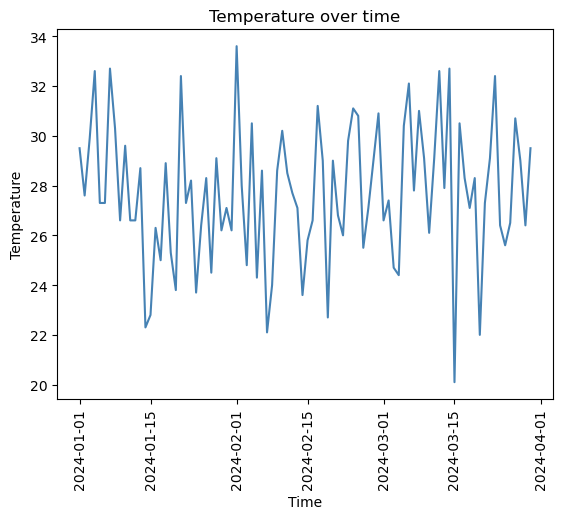

In [70]:
#Temperature over time
import pandas as pd
import matplotlib.pyplot as plt
plt.plot(df['Date'],df['Temperature'],linestyle='-',color='steelblue')
plt.xticks(rotation=90)
plt.xlabel('Time')
plt.ylabel('Temperature')
plt.title('Temperature over time')
plt.savefig("Temperature over time.png")
plt.show()

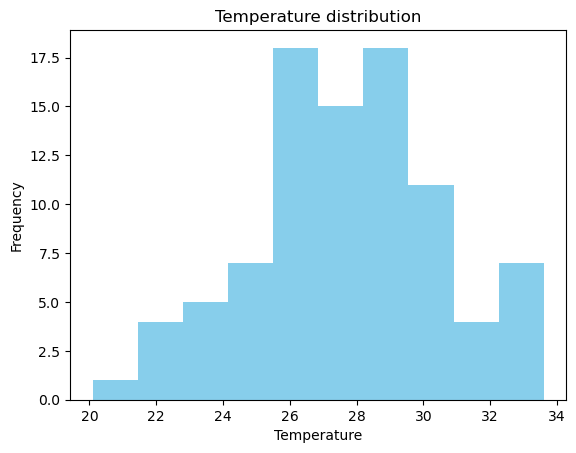

In [73]:
# Temperature distribution
import pandas as pd
import matplotlib.pyplot as plt
plt.hist(df['Temperature'],color='skyblue')
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.title("Temperature distribution")
plt.savefig("Temperature distribution.png")
plt.show()

In [94]:
df['rain_by_month'] = df.groupby('Month')['Rainfall'].transform(sum)
print(df['rain_by_month'])

0     72.1
1     72.1
2     72.1
3     72.1
4     72.1
      ... 
85    60.2
86    60.2
87    60.2
88    60.2
89    60.2
Name: rain_by_month, Length: 90, dtype: float64


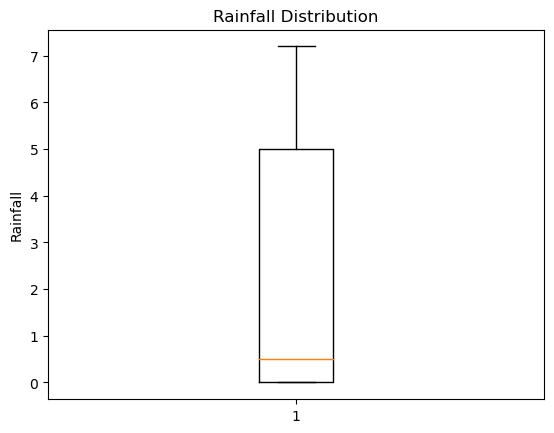

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
plt.boxplot(df['Rainfall'])
plt.ylabel("Rainfall")
plt.title("Rainfall Distribution")
plt.savefig("rainbox.png")
plt.show()

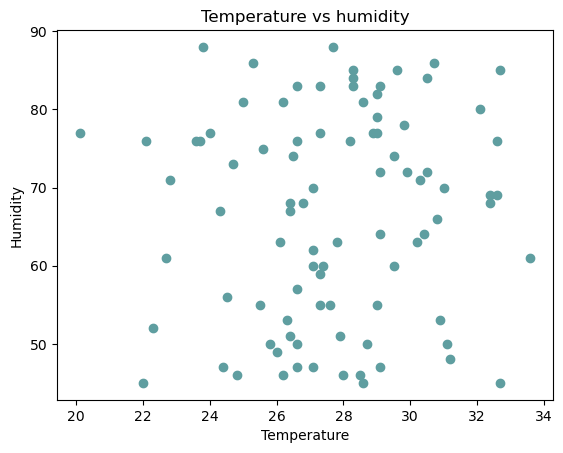

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
plt.scatter(df['Temperature'],df['Humidity'],color='cadetblue',marker='o')
plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.title("Temperature vs humidity")
plt.savefig("Temp vs humidity.png")
plt.show()         #Doesnt have a strong relationship

In [103]:
import seaborn as sns 
import matplotlib.pyplot as plt 
corr=(df[['Temperature','Humidity','WindSpeed','Rainfall']].corr()
sns.heatmap(corr,annot=True,cmap='BuPu')
ply.show()

SyntaxError: invalid syntax (3320798770.py, line 4)

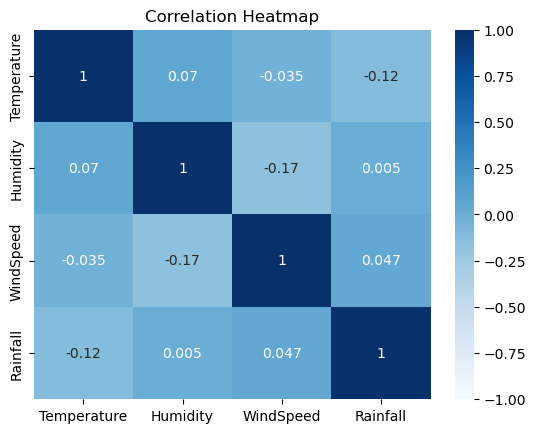

In [108]:
import seaborn as sns
import matplotlib.pyplot as plt
corr = df[['Temperature','Humidity','WindSpeed','Rainfall']].corr()
sns.heatmap(corr, annot=True, cmap='Blues',vmin=-1,vmax=+1)
plt.title("Correlation Heatmap")
plt.savefig("corr_heatmap.png")
plt.show()


- The dataset covers 90 days (Jan–Mar 2024) with no missing values or duplicates.\## Insights
- 90 days of clean weather data (Jan–Mar 2024), no missing values.
- No outliers found.
- Average temperature: 27.7°C (hottest: 33.6°C, coldest: 20.1°C)
- Average humidity: 66%
- Average wind speed: 13 km/h, slightly increasing over the 3 months
- Average rainfall: 2.4mm/day, February had the most rainfall
- Temperature, humidity, wind, and rainfall showed very weak correlation with each 
  other they don't have strong relationship with each other in this dataset.
